<a href="https://colab.research.google.com/github/nasif-raihan/GSU/blob/main/CSCI_5535_Clustering_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clustering in Machine Learning


---

**Lab Objectives:**
- Define clustering and explain its purpose in unsupervised machine learning
- Identify the benefits, drawbacks, and appropriate use cases for clustering
- Implement K-Means, Hierarchical (Agglomerative), and DBSCAN clustering algorithms
- Apply clustering to real-world scenarios including customer segmentation, document grouping, anomaly detection, and image compression
- Evaluate clustering quality using silhouette score, inertia, and the elbow method

**Total Points: 100**

| Part | Topic | Points |
|------|-------|--------|
| 1 | Understanding Clustering Concepts | 15 |
| 2 | K-Means Clustering | 25 |
| 3 | Hierarchical (Agglomerative) Clustering | 20 |
| 4 | DBSCAN Clustering | 20 |
| 5 | Clustering Evaluation & Model Selection | 10 |
| 6 | Real-World Application Challenge | 10 |

**References:**
- Geron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.), Chapter 9.
- Google Developers. *Machine Learning Crash Course: Clustering.* https://developers.google.com/machine-learning/clustering
- IBM. *What is Clustering?* https://www.ibm.com/think/topics/clustering
- IBM. *Unsupervised Machine Learning Professional Certificate.* Coursera.
- Scikit-learn Documentation. *Clustering.* https://scikit-learn.org/stable/modules/clustering.html
- Bishop, C. (2006). *Pattern Recognition and Machine Learning*, Chapter 9.

---
## Part 0: Setup and Imports

Run the cell below to load all required libraries and the GradeTracker.

In [1]:
# ============================================================
# SETUP - Run this cell first!
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.datasets import make_blobs, make_moons, load_iris, load_wine
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

# GradeTracker for automated scoring
class GradeTracker:
    def __init__(self):
        self.scores = {}

    def record(self, part, points_earned, points_possible, label=""):
        key = f"{part}: {label}" if label else part
        self.scores[key] = (points_earned, points_possible)
        if points_earned == points_possible:
            print(f"\u2705 {key}: {points_earned}/{points_possible} points")
        elif points_earned > 0:
            print(f"\u2705 {key}: {points_earned}/{points_possible} points (partial credit)")
        else:
            print(f"\u274C {key}: {points_earned}/{points_possible} points")

    def summary(self):
        print("\n" + "=" * 55)
        print("GRADE SUMMARY")
        print("=" * 55)
        total_earned = 0
        total_possible = 0
        for key, (earned, possible) in self.scores.items():
            status = "\u2705" if earned == possible else ("\u2705" if earned > 0 else "\u274C")
            print(f"  {status} {key}: {earned}/{possible}")
            total_earned += earned
            total_possible += possible
        print("-" * 55)
        pct = (total_earned / total_possible * 100) if total_possible > 0 else 0
        print(f"  TOTAL: {total_earned}/{total_possible} ({pct:.1f}%)")
        print("=" * 55)

tracker = GradeTracker()
print("\u2705 All libraries loaded and GradeTracker initialized.")
print("   scikit-learn, NumPy, pandas, matplotlib ready.")

✅ All libraries loaded and GradeTracker initialized.
   scikit-learn, NumPy, pandas, matplotlib ready.


---
## Part 1: Understanding Clustering Concepts (15 points)

### What Is Clustering?

**Clustering** is an **unsupervised machine learning** technique that groups a set of data points into subsets (called **clusters**) such that data points within the same cluster are more similar to each other than to those in other clusters.

Unlike supervised learning (classification, regression), clustering operates on **unlabeled data** — there is no target variable to guide the algorithm. Instead, the algorithm discovers natural structure in the data on its own.

> *"Clustering is a data mining technique which groups unlabeled data based on their similarities or differences."*
> — IBM, *What is Clustering?*

> *"The k-means algorithm is employed [in Google MLCC] to group data based on a defined similarity metric. Evaluating and adjusting clustering outcomes is an iterative process."*
> — Google ML Crash Course, *Clustering Workflow*

### Purpose of Clustering

Clustering serves several key purposes in data science and machine learning:

1. **Exploratory Data Analysis (EDA):** Discover hidden patterns, groupings, and structure in datasets before applying supervised methods.
2. **Data Preprocessing:** Segment large datasets into meaningful groups for downstream tasks (e.g., training separate models per cluster).
3. **Dimensionality Reduction:** Represent each data point by its cluster assignment, compressing information.
4. **Anomaly / Outlier Detection:** Points that do not fit well into any cluster may be anomalies or outliers.
5. **Feature Engineering:** Cluster membership can serve as a new feature for supervised learning models.

### Benefits of Clustering

| Benefit | Description |
|---------|-------------|
| **No labels required** | Works on unlabeled data, which is abundant and cheap to collect. |
| **Reveals hidden structure** | Finds natural groupings humans might miss in high-dimensional data. |
| **Versatile applications** | Used in marketing, biology, security, NLP, image processing, and more. |
| **Scalable** | Algorithms like K-Means are computationally efficient on large datasets. |
| **Complementary** | Can be combined with supervised methods (semi-supervised learning). |

### Drawbacks of Clustering

| Drawback | Description |
|----------|-------------|
| **No ground truth** | Without labels, it is difficult to objectively validate results. |
| **Sensitive to parameters** | Number of clusters (k), distance metrics, and scaling affect results. |
| **Interpretability varies** | Cluster meaning must be inferred by domain experts — not automatic. |
| **Curse of dimensionality** | Performance degrades in very high-dimensional feature spaces. |
| **Shape assumptions** | Some algorithms (K-Means) assume spherical clusters and fail on complex shapes. |

### Where Is Clustering Used? Real-World Applications

| Domain | Application | Example |
|--------|-------------|---------|
| **Marketing** | Customer segmentation | Group shoppers by purchasing behavior for targeted campaigns |
| **Healthcare** | Patient stratification | Cluster patients by symptoms to identify disease subtypes |
| **Cybersecurity** | Intrusion detection | Flag network traffic patterns that deviate from normal clusters |
| **Biology** | Gene expression analysis | Group genes with similar expression profiles across experiments |
| **NLP** | Document / topic clustering | Organize news articles into topic groups automatically |
| **Computer Vision** | Image segmentation & compression | Reduce color palettes by clustering pixel colors |
| **Finance** | Fraud detection | Identify unusual transaction patterns as outlier clusters |
| **Urban Planning** | Geographic analysis | Cluster GPS coordinates to identify activity hotspots |
| **Recommendation Systems** | User grouping | Group users with similar preferences to improve suggestions |
| **Astronomy** | Star / galaxy classification | Cluster celestial objects by spectral and brightness features |

---

### Worked Example: Visual Intuition for Clustering

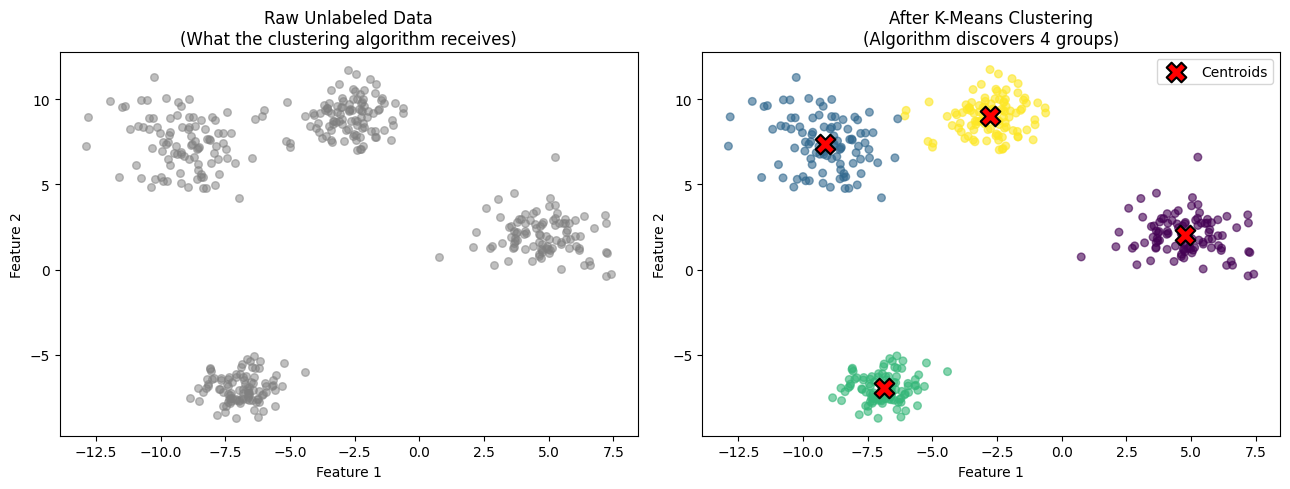

Notice: The algorithm found 4 groups WITHOUT any labels!
The red X markers are the cluster centroids (centers).


In [2]:
# Worked Example: Visualize how clustering discovers structure
# Generate synthetic data with 4 natural clusters
X_demo, y_demo = make_blobs(n_samples=400, centers=4,
                            cluster_std=[1.0, 1.2, 0.8, 1.5],
                            random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Raw unlabeled data (what the algorithm sees)
axes[0].scatter(X_demo[:, 0], X_demo[:, 1], c='gray', alpha=0.5, s=30)
axes[0].set_title("Raw Unlabeled Data\n(What the clustering algorithm receives)", fontsize=12)
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

# Right: After K-Means clustering
km_demo = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_demo = km_demo.fit_predict(X_demo)
centers_demo = km_demo.cluster_centers_

scatter = axes[1].scatter(X_demo[:, 0], X_demo[:, 1], c=labels_demo,
                          cmap='viridis', alpha=0.6, s=30)
axes[1].scatter(centers_demo[:, 0], centers_demo[:, 1],
                c='red', marker='X', s=200, edgecolors='black', linewidths=1.5,
                label='Centroids')
axes[1].set_title("After K-Means Clustering\n(Algorithm discovers 4 groups)", fontsize=12)
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].legend()

plt.tight_layout()
plt.show()
print("Notice: The algorithm found 4 groups WITHOUT any labels!")
print("The red X markers are the cluster centroids (centers).")

### Exercise 1.1: Identify Clustering Use Cases (5 points)

A data science team is presented with the following five scenarios. For each, determine whether **clustering is appropriate** (`True`) or **not appropriate** (`False`).

Complete the dictionary below. Each correct answer earns 1 point.

In [3]:
# Exercise 1.1: Set each value to True (clustering appropriate) or False (not appropriate)

clustering_use_cases = {
    # Scenario A: An e-commerce company wants to group customers by browsing
    #             and purchase behavior to create targeted marketing segments.
    "scenario_a": True,  # Replace None

    # Scenario B: A hospital wants to predict whether a patient has diabetes
    #             based on blood glucose level, BMI, and age (labeled dataset).
    "scenario_b": False,  # Replace None

    # Scenario C: A news platform wants to automatically organize thousands
    #             of unlabeled articles into topic groups.
    "scenario_c": True,  # Replace None

    # Scenario D: A teacher wants to calculate the average test score of a class.
    "scenario_d": False,  # Replace None

    # Scenario E: A cybersecurity firm wants to detect unusual network traffic
    #             patterns that may indicate an intrusion, without labeled attack data.
    "scenario_e": True,  # Replace None
}

In [4]:
# --- Tester 1.1 (5 points) ---
score_1_1 = 0
answer_key_1_1 = {"scenario_a": True, "scenario_b": False, "scenario_c": True,
                   "scenario_d": False, "scenario_e": True}
for key in answer_key_1_1:
    val = clustering_use_cases.get(key)
    if val is answer_key_1_1[key]:
        score_1_1 += 1
        print(f"\u2705 {key}: Correct!")
    else:
        print(f"\u274C {key}: Incorrect. Expected {answer_key_1_1[key]}, got {val}")
tracker.record("Part 1", score_1_1, 5, "Use Case Identification")

✅ scenario_a: Correct!
✅ scenario_b: Correct!
✅ scenario_c: Correct!
✅ scenario_d: Correct!
✅ scenario_e: Correct!
✅ Part 1: Use Case Identification: 5/5 points


### Exercise 1.2: Benefits vs. Drawbacks Classification (5 points)

Classify each statement as either `"benefit"` or `"drawback"` of clustering. Each correct answer earns 1 point.

In [5]:
# Exercise 1.2: Classify each statement as "benefit" or "drawback"

benefit_or_drawback = {
    # Statement A: "Clustering does not require labeled training data."
    "statement_a": "benefit",  # Replace None with "benefit" or "drawback"

    # Statement B: "Results are highly sensitive to the choice of k in K-Means."
    "statement_b": "drawback",

    # Statement C: "Clustering can reveal hidden patterns that humans miss."
    "statement_c": "benefit",

    # Statement D: "Without ground truth labels, it is hard to validate cluster quality objectively."
    "statement_d": "drawback",

    # Statement E: "K-Means is computationally efficient and scales well to large datasets."
    "statement_e": "benefit",
}

In [6]:
# --- Tester 1.2 (5 points) ---
score_1_2 = 0
answer_key_1_2 = {"statement_a": "benefit", "statement_b": "drawback",
                   "statement_c": "benefit", "statement_d": "drawback",
                   "statement_e": "benefit"}
for key in answer_key_1_2:
    val = benefit_or_drawback.get(key)
    if isinstance(val, str) and val.strip().lower() == answer_key_1_2[key]:
        score_1_2 += 1
        print(f"\u2705 {key}: Correct!")
    else:
        print(f"\u274C {key}: Incorrect. Expected '{answer_key_1_2[key]}', got '{val}'")
tracker.record("Part 1", score_1_2, 5, "Benefits vs Drawbacks")

✅ statement_a: Correct!
✅ statement_b: Correct!
✅ statement_c: Correct!
✅ statement_d: Correct!
✅ statement_e: Correct!
✅ Part 1: Benefits vs Drawbacks: 5/5 points


### Exercise 1.3: Supervised vs. Unsupervised (5 points)

Complete the function below that takes a short description string and returns `"supervised"` or `"unsupervised"` based on the ML category. Use the keywords in the description to decide.

In [7]:
# Exercise 1.3: Complete the function
def classify_ml_type(description):
    """
    Given a description string, return 'supervised' if the task involves
    labeled data / predicting a known target, or 'unsupervised' if it involves
    finding hidden patterns in unlabeled data.

    Hint: Look for keywords like 'labeled', 'predict', 'classify' (supervised)
          vs. 'unlabeled', 'group', 'cluster', 'segment', 'pattern' (unsupervised).

    Parameters
    ----------
    description : str

    Returns
    -------
    str : 'supervised' or 'unsupervised'
    """
    # YOUR CODE HERE
    supervised_labels = ["labeled", "predict", "classify"]
    unsupervised_labels = ["unlabeled", "group", "cluster", "segment", "pattern"]

    if any(label in description.lower().split() for label in supervised_labels):
        return "supervised"
    elif any(label in description.lower().split() for label in unsupervised_labels):
        return "unsupervised"
    else:
        return "unknown"

In [8]:
# --- Tester 1.3 (5 points) ---
score_1_3 = 0
test_cases_1_3 = [
    ("Predict house prices using labeled historical sales data.", "supervised"),
    ("Group customer transactions to find natural spending segments.", "unsupervised"),
    ("Classify emails as spam or not spam using a labeled dataset.", "supervised"),
    ("Cluster unlabeled medical images to discover pattern groups.", "unsupervised"),
    ("Predict whether a student will pass based on labeled attendance data.", "supervised"),
]
for desc, expected in test_cases_1_3:
    try:
        result = classify_ml_type(desc)
        if isinstance(result, str) and result.strip().lower() == expected:
            score_1_3 += 1
            print(f"\u2705 Correct: '{desc[:50]}...' -> {expected}")
        else:
            print(f"\u274C Wrong: '{desc[:50]}...' Expected '{expected}', got '{result}'")
    except Exception as e:
        print(f"\u274C Error on '{desc[:50]}...': {e}")
tracker.record("Part 1", score_1_3, 5, "Supervised vs Unsupervised")

✅ Correct: 'Predict house prices using labeled historical sale...' -> supervised
✅ Correct: 'Group customer transactions to find natural spendi...' -> unsupervised
✅ Correct: 'Classify emails as spam or not spam using a labele...' -> supervised
✅ Correct: 'Cluster unlabeled medical images to discover patte...' -> unsupervised
✅ Correct: 'Predict whether a student will pass based on label...' -> supervised
✅ Part 1: Supervised vs Unsupervised: 5/5 points


---
## Part 2: K-Means Clustering (25 points)

### How K-Means Works

K-Means is one of the most widely used clustering algorithms. It partitions data into **k** clusters by iteratively:

1. **Initialize** k cluster centroids (randomly or with K-Means++).
2. **Assign** each data point to the nearest centroid (based on Euclidean distance).
3. **Update** each centroid to the mean position of all points assigned to it.
4. **Repeat** steps 2-3 until centroids stabilize (converge) or a max iteration limit is reached.

**Key Properties:**
- Requires specifying **k** (number of clusters) in advance
- Uses **Euclidean distance** by default
- Converges to a **local optimum** (results depend on initialization)
- **K-Means++** initialization reduces sensitivity to starting positions
- Works best with **spherical, equally-sized clusters**

> Geron (2022, Ch. 9): K-Means is fast, scalable, but assumes clusters are convex and isotropic. Always scale features before applying K-Means.

### Real-World Application 1: Customer Segmentation

A retail company wants to segment customers based on **Annual Income** and **Spending Score** for targeted marketing campaigns. This is one of the most common business applications of clustering.

In [9]:
# ============================================================
# Worked Example: Customer Segmentation with K-Means
# ============================================================
# Simulate a customer dataset (inspired by Mall Customers dataset)
np.random.seed(42)
n_customers = 200

# Generate 5 natural customer segments
segments = {
    "Budget Savers":     {"income": (20, 8),  "spending": (20, 8)},
    "Low-Income Spenders": {"income": (25, 7),  "spending": (75, 8)},
    "Middle Class":      {"income": (55, 10), "spending": (50, 10)},
    "High-Income Savers":  {"income": (85, 8),  "spending": (20, 8)},
    "Premium Spenders":  {"income": (85, 8),  "spending": (80, 8)},
}

incomes, spendings = [], []
for seg_name, params in segments.items():
    n = 40
    incomes.extend(np.random.normal(params["income"][0], params["income"][1], n))
    spendings.extend(np.random.normal(params["spending"][0], params["spending"][1], n))

customers = pd.DataFrame({
    "Annual_Income_k": np.clip(incomes, 5, 120),
    "Spending_Score": np.clip(spendings, 1, 100)
})
print(f"Customer dataset shape: {customers.shape}")
print(customers.describe().round(1))

Customer dataset shape: (200, 2)
       Annual_Income_k  Spending_Score
count            200.0           200.0
mean              53.5            50.0
std               29.2            27.2
min                5.0             1.0
25%               24.2            22.9
50%               56.1            52.9
75%               81.3            75.9
max              102.0            97.5


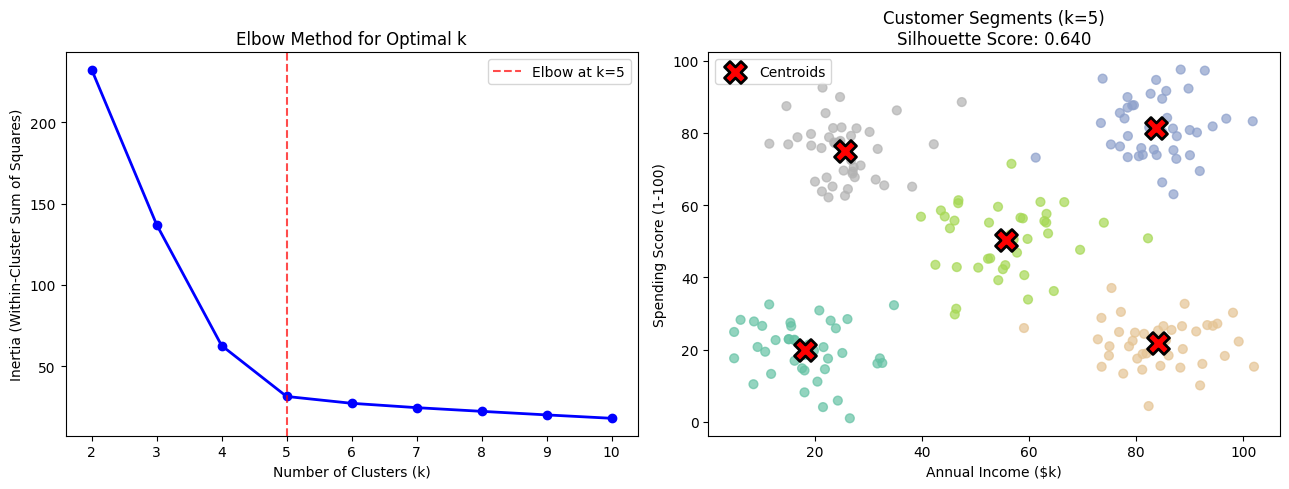


Cluster Summary (mean values):
         Annual_Income_k  Spending_Score
Cluster                                 
0                   18.3            19.8
1                   83.8            81.5
2                   55.7            50.4
3                   84.1            21.8
4                   25.6            75.1


In [10]:
# Step 1: Scale the features (CRITICAL for K-Means!)
scaler = StandardScaler()
X_customers = scaler.fit_transform(customers[["Annual_Income_k", "Spending_Score"]])

# Step 2: Find optimal k using the Elbow Method
inertias = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_customers)
    inertias.append(km.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Elbow plot
axes[0].plot(K_range, inertias, 'bo-', linewidth=2)
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia (Within-Cluster Sum of Squares)")
axes[0].set_title("Elbow Method for Optimal k")
axes[0].axvline(x=5, color='red', linestyle='--', alpha=0.7, label='Elbow at k=5')
axes[0].legend()

# Step 3: Fit K-Means with k=5
km_final = KMeans(n_clusters=5, random_state=42, n_init=10)
customer_labels = km_final.fit_predict(X_customers)

# Visualize the clusters (in original scale)
scatter = axes[1].scatter(customers["Annual_Income_k"], customers["Spending_Score"],
                          c=customer_labels, cmap='Set2', alpha=0.7, s=40)
# Plot centroids in original scale
centers_orig = scaler.inverse_transform(km_final.cluster_centers_)
axes[1].scatter(centers_orig[:, 0], centers_orig[:, 1],
                c='red', marker='X', s=250, edgecolors='black', linewidths=2,
                label='Centroids', zorder=5)
axes[1].set_xlabel("Annual Income ($k)")
axes[1].set_ylabel("Spending Score (1-100)")
axes[1].set_title(f"Customer Segments (k=5)\nSilhouette Score: {silhouette_score(X_customers, customer_labels):.3f}")
axes[1].legend()

plt.tight_layout()
plt.show()

# Summarize segments
customers["Cluster"] = customer_labels
print("\nCluster Summary (mean values):")
print(customers.groupby("Cluster").mean().round(1))

### Real-World Application 2: Image Color Compression

K-Means can reduce the number of colors in an image by clustering pixel colors. Each pixel is replaced by its cluster centroid color, effectively compressing the image.

Total unique colors in original: 9556


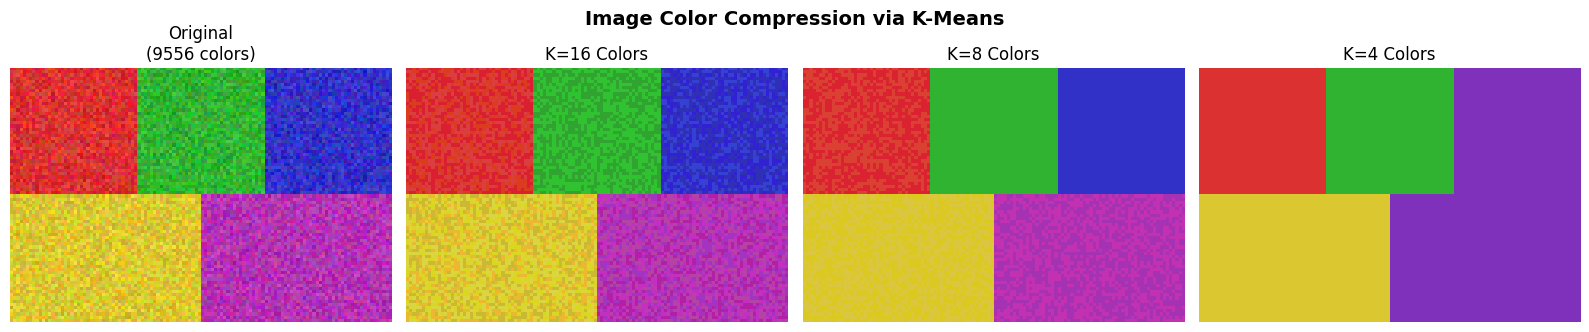

K-Means clusters pixel RGB values, replacing each with its centroid color.


In [11]:
# ============================================================
# Worked Example: Image Color Compression with K-Means
# ============================================================
# Create a synthetic colorful image for demonstration
np.random.seed(7)
img_height, img_width = 80, 120
image = np.zeros((img_height, img_width, 3), dtype=np.uint8)

# Paint regions with different colors
image[:40, :40] = [220, 50, 50]      # Red region
image[:40, 40:80] = [50, 180, 50]    # Green region
image[:40, 80:] = [50, 50, 200]      # Blue region
image[40:, :60] = [220, 200, 50]     # Yellow region
image[40:, 60:] = [180, 50, 180]     # Purple region

# Add noise to make it more realistic
image = np.clip(image.astype(np.int16) + np.random.randint(-30, 30, image.shape), 0, 255).astype(np.uint8)

# Reshape: each pixel is a 3D point (R, G, B)
pixels = image.reshape(-1, 3).astype(np.float64)
print(f"Total unique colors in original: {len(np.unique(pixels, axis=0))}")

# Compress to different numbers of colors
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))

axes[0].imshow(image)
axes[0].set_title(f"Original\n({len(np.unique(pixels, axis=0))} colors)")
axes[0].axis("off")

for i, n_colors in enumerate([16, 8, 4]):
    km_img = KMeans(n_clusters=n_colors, random_state=42, n_init=4)
    labels_img = km_img.fit_predict(pixels)
    compressed = km_img.cluster_centers_[labels_img].reshape(image.shape).astype(np.uint8)

    axes[i+1].imshow(compressed)
    axes[i+1].set_title(f"K={n_colors} Colors")
    axes[i+1].axis("off")

plt.suptitle("Image Color Compression via K-Means", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print("K-Means clusters pixel RGB values, replacing each with its centroid color.")

### Exercise 2.1: Implement K-Means on the Iris Dataset (10 points)

The Iris dataset contains 4 features for 150 flowers from 3 species. Since clustering is unsupervised, we will **ignore the species labels** and see if K-Means can discover the 3 natural groups.

Complete the steps below.

In [12]:
# Exercise 2.1: K-Means on Iris

# Step 1: Load the Iris dataset
iris = load_iris()
X_iris = iris.data  # 150 samples, 4 features

# Step 2: Scale the features using StandardScaler
# YOUR CODE: Create a StandardScaler, fit_transform X_iris, store result in X_iris_scaled
scaler = StandardScaler()
X_iris_scaled = scaler.fit_transform(X_iris)  # Replace with your code

# Step 3: Fit KMeans with n_clusters=3, random_state=42, n_init=10
# YOUR CODE: Create and fit KMeans, store the model in kmeans_iris
kmeans_iris = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_iris_scaled)

# Step 4: Get the cluster labels and silhouette score
# YOUR CODE: Get labels from kmeans_iris (use .labels_ attribute)
iris_labels = kmeans_iris.labels_  # Replace with your code

# YOUR CODE: Compute silhouette_score(X_iris_scaled, iris_labels)
iris_silhouette = silhouette_score(X_iris_scaled, iris_labels)  # Replace with your code

print(f"Cluster labels shape: {np.array(iris_labels).shape if iris_labels is not None else 'None'}")
print(f"Unique clusters: {np.unique(iris_labels) if iris_labels is not None else 'None'}")
print(f"Silhouette Score: {iris_silhouette}")

Cluster labels shape: (150,)
Unique clusters: [0 1 2]
Silhouette Score: 0.45994823920518635


In [13]:
# --- Tester 2.1 (10 points) ---
score_2_1 = 0

# Test scaling (2 pts)
if X_iris_scaled is not None and X_iris_scaled.shape == (150, 4):
    mean_check = np.abs(X_iris_scaled.mean(axis=0)).max() < 1e-10
    std_check = np.allclose(X_iris_scaled.std(axis=0, ddof=0), 1.0, atol=0.01)
    if mean_check and std_check:
        score_2_1 += 2
        print("\u2705 Scaling: Correct (zero mean, unit variance)")
    else:
        score_2_1 += 1
        print("\u2705 Scaling: Partial - shape correct but values not fully standardized")
else:
    print("\u274C Scaling: X_iris_scaled should have shape (150, 4)")

# Test KMeans model (3 pts)
if kmeans_iris is not None and hasattr(kmeans_iris, 'cluster_centers_'):
    if kmeans_iris.cluster_centers_.shape == (3, 4):
        score_2_1 += 2
        print("\u2705 KMeans model: Correct (3 clusters, 4 features)")
    else:
        print("\u274C KMeans model: Expected 3 clusters with 4 features")
    if hasattr(kmeans_iris, 'n_clusters') and kmeans_iris.n_clusters == 3:
        score_2_1 += 1
        print("\u2705 n_clusters=3: Correct")
    else:
        print("\u274C n_clusters should be 3")
else:
    print("\u274C KMeans model not fitted. Use KMeans(n_clusters=3, random_state=42, n_init=10).fit()")

# Test labels (2 pts)
if iris_labels is not None and len(iris_labels) == 150:
    if len(np.unique(iris_labels)) == 3:
        score_2_1 += 2
        print("\u2705 Labels: Correct (150 labels, 3 unique clusters)")
    else:
        score_2_1 += 1
        print("\u2705 Labels: Partial - 150 labels but unexpected number of clusters")
else:
    print("\u274C Labels: Should be array of length 150")

# Test silhouette score (3 pts)
if iris_silhouette is not None and isinstance(iris_silhouette, (float, np.floating)):
    if 0.3 < iris_silhouette < 0.8:
        score_2_1 += 3
        print(f"\u2705 Silhouette score: {iris_silhouette:.4f} (reasonable range)")
    else:
        score_2_1 += 1
        print(f"\u2705 Silhouette score computed but value {iris_silhouette:.4f} seems unusual")
else:
    print("\u274C Silhouette score: Should be a float. Use silhouette_score(X_iris_scaled, iris_labels)")

tracker.record("Part 2", score_2_1, 10, "K-Means Iris")

✅ Scaling: Correct (zero mean, unit variance)
✅ KMeans model: Correct (3 clusters, 4 features)
✅ n_clusters=3: Correct
✅ Labels: Correct (150 labels, 3 unique clusters)
✅ Silhouette score: 0.4599 (reasonable range)
✅ Part 2: K-Means Iris: 10/10 points


### Exercise 2.2: Elbow Method - Find Optimal k (8 points)

Implement the elbow method on the Wine dataset. Compute inertia for k = 2 through 10, and identify the optimal k.

In [14]:
# Exercise 2.2: Elbow Method on Wine dataset

# Step 1: Load and scale the Wine dataset
wine = load_wine()
X_wine = wine.data  # 178 samples, 13 features

scaler_wine = StandardScaler()
X_wine_scaled = scaler_wine.fit_transform(X_wine)

# Step 2: Compute inertia for k=2 to k=10
# YOUR CODE: Create a list called 'inertia_values' containing the inertia
# for KMeans with k=2, 3, 4, ..., 10 (each with random_state=42, n_init=10)
inertia_values = []  # Replace: append inertia for each k in range(2, 11)

# YOUR CODE HERE - use a for loop over range(2, 11)
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_wine_scaled)
    inertia_values.append(kmeans.inertia_)


# Step 3: Based on the elbow plot, what is the optimal k?
# YOUR CODE: Set optimal_k_wine to the k value at the elbow
optimal_k_wine = 3  # Replace with an integer (2-10)

print(f"Inertia values: {[round(v, 1) for v in inertia_values]}")
print(f"Your chosen optimal k: {optimal_k_wine}")

Inertia values: [1658.8, 1277.9, 1175.4, 1109.5, 1046.0, 981.6, 935.2, 889.9, 845.9]
Your chosen optimal k: 3


✅ Inertia values: 9 values, monotonically decreasing
✅ Inertia magnitude: Reasonable for scaled Wine data
✅ Optimal k = 3: Correct! (Wine has 3 cultivars)
✅ Part 2: Elbow Method Wine: 8/8 points


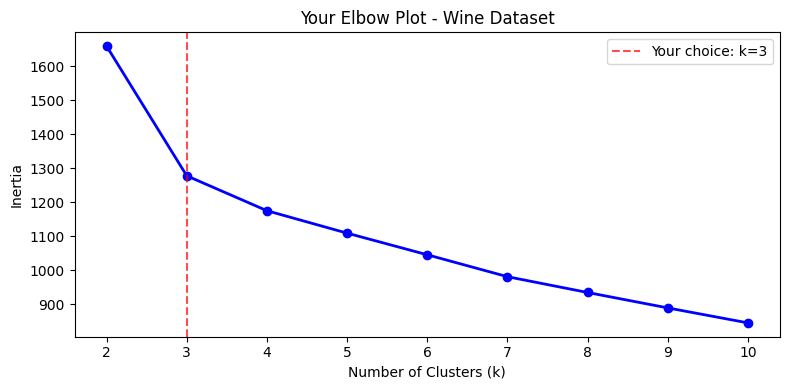

In [15]:
# --- Tester 2.2 (8 points) ---
score_2_2 = 0

# Test inertia list (4 pts)
if isinstance(inertia_values, list) and len(inertia_values) == 9:
    # Verify inertia is monotonically decreasing
    if all(inertia_values[i] >= inertia_values[i+1] for i in range(len(inertia_values)-1)):
        score_2_2 += 3
        print("\u2705 Inertia values: 9 values, monotonically decreasing")
    else:
        score_2_2 += 1
        print("\u2705 Inertia values: Partial - 9 values but not monotonically decreasing")
    # Check reasonable range
    if inertia_values[0] > 100:
        score_2_2 += 1
        print("\u2705 Inertia magnitude: Reasonable for scaled Wine data")
    else:
        print("\u274C Inertia magnitude seems too small - did you scale the data?")
else:
    print(f"\u274C Inertia values: Expected list of 9 values, got {type(inertia_values).__name__} of length {len(inertia_values) if hasattr(inertia_values, '__len__') else '?'}")

# Test optimal k (4 pts)
if optimal_k_wine is not None and isinstance(optimal_k_wine, int):
    if optimal_k_wine == 3:
        score_2_2 += 4
        print(f"\u2705 Optimal k = {optimal_k_wine}: Correct! (Wine has 3 cultivars)")
    elif optimal_k_wine in [2, 4]:
        score_2_2 += 2
        print(f"\u2705 Optimal k = {optimal_k_wine}: Close, but k=3 is the standard elbow for Wine data")
    else:
        print(f"\u274C Optimal k = {optimal_k_wine}: The elbow typically occurs at k=3 for the Wine dataset")
else:
    print("\u274C optimal_k_wine should be an integer between 2 and 10")

tracker.record("Part 2", score_2_2, 8, "Elbow Method Wine")

# Visualize the student's elbow plot
if len(inertia_values) == 9:
    plt.figure(figsize=(8, 4))
    plt.plot(range(2, 11), inertia_values, 'bo-', linewidth=2)
    if optimal_k_wine:
        plt.axvline(x=optimal_k_wine, color='red', linestyle='--', alpha=0.7,
                     label=f'Your choice: k={optimal_k_wine}')
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia")
    plt.title("Your Elbow Plot - Wine Dataset")
    plt.legend()
    plt.tight_layout()
    plt.show()

### Exercise 2.3: Customer Segmentation Application (7 points)

Given a synthetic customer dataset, apply K-Means clustering to segment customers into 4 groups. Return a dictionary with the results.

In [16]:
# Exercise 2.3: Customer segmentation
np.random.seed(99)
cust_data = pd.DataFrame({
    "Recency": np.concatenate([np.random.normal(m, 5, 50) for m in [10, 30, 60, 80]]),
    "Frequency": np.concatenate([np.random.normal(m, 3, 50) for m in [50, 30, 10, 5]]),
    "MonetaryValue": np.concatenate([np.random.normal(m, 20, 50) for m in [500, 300, 100, 50]])
})

def segment_customers(df, n_clusters=4, random_state=42):
    """
    Segment customers using K-Means clustering.

    Steps:
      1. Scale the DataFrame features using StandardScaler.
      2. Fit KMeans with the given n_clusters, random_state, and n_init=10.
      3. Return a dictionary with:
         - 'labels': array of cluster labels
         - 'silhouette': silhouette score (float)
         - 'inertia': model inertia (float)
         - 'centers': cluster centers in ORIGINAL (unscaled) space, shape (n_clusters, 3)

    Parameters
    ----------
    df : pd.DataFrame with columns Recency, Frequency, MonetaryValue
    n_clusters : int
    random_state : int

    Returns
    -------
    dict with keys 'labels', 'silhouette', 'inertia', 'centers'
    """
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df)

    kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
    labels = kmeans.fit_predict(scaled_data)

    silhouette = silhouette_score(scaled_data, labels)
    inertia = kmeans.inertia_

    # Inverse transform to get centroids in the original scale
    centers = scaler.inverse_transform(kmeans.cluster_centers_)

    return {
        'labels': labels,
        'silhouette': silhouette,
        'inertia': inertia,
        'centers': centers
    }

# Run your function
result_2_3 = segment_customers(cust_data)
if result_2_3:
    print("Labels sample:", result_2_3.get('labels', [])[:10])
    print("Silhouette:", result_2_3.get('silhouette'))
    print("Inertia:", result_2_3.get('inertia'))

Labels sample: [2 2 2 2 2 2 2 2 2 2]
Silhouette: 0.6885520324284857
Inertia: 13.93062860684326


In [17]:
# --- Tester 2.3 (7 points) ---
score_2_3 = 0

if result_2_3 is not None and isinstance(result_2_3, dict):
    # Labels (2 pts)
    labels = result_2_3.get('labels')
    if labels is not None and len(labels) == 200 and len(np.unique(labels)) == 4:
        score_2_3 += 2
        print("\u2705 Labels: 200 labels, 4 unique clusters")
    else:
        print(f"\u274C Labels: Expected 200 labels with 4 clusters")

    # Silhouette (2 pts)
    sil = result_2_3.get('silhouette')
    if sil is not None and isinstance(sil, (float, np.floating)) and 0.2 < sil < 0.9:
        score_2_3 += 2
        print(f"\u2705 Silhouette: {sil:.4f} (valid range)")
    else:
        print(f"\u274C Silhouette: Expected float in (0.2, 0.9), got {sil}")

    # Inertia (1 pt)
    inertia = result_2_3.get('inertia')
    if inertia is not None and isinstance(inertia, (float, np.floating)) and inertia > 0:
        score_2_3 += 1
        print(f"\u2705 Inertia: {inertia:.2f}")
    else:
        print(f"\u274C Inertia: Expected positive float, got {inertia}")

    # Centers in original space (2 pts)
    centers = result_2_3.get('centers')
    if centers is not None and np.array(centers).shape == (4, 3):
        # Check they are in original scale (not standardized ~ 0)
        if np.abs(np.array(centers)).mean() > 5:
            score_2_3 += 2
            print(f"\u2705 Centers: Shape (4,3), in original scale")
        else:
            score_2_3 += 1
            print("\u2705 Centers: Shape correct but values look standardized - use inverse_transform")
    else:
        print(f"\u274C Centers: Expected shape (4, 3)")
else:
    print("\u274C Function returned None - implement segment_customers()")

tracker.record("Part 2", score_2_3, 7, "Customer Segmentation")

✅ Labels: 200 labels, 4 unique clusters
✅ Silhouette: 0.6886 (valid range)
✅ Inertia: 13.93
✅ Centers: Shape (4,3), in original scale
✅ Part 2: Customer Segmentation: 7/7 points


---
## Part 3: Hierarchical (Agglomerative) Clustering (20 points)

### How Agglomerative Clustering Works

Agglomerative clustering is a **bottom-up** hierarchical approach:

1. **Start** with each data point as its own cluster (n clusters for n points).
2. **Merge** the two closest clusters into one (based on a linkage criterion).
3. **Repeat** step 2 until all points belong to a single cluster (or until the desired number of clusters is reached).

**Linkage Criteria:**
- **Ward** (default): Minimizes the total within-cluster variance. Tends to produce equally-sized clusters.
- **Complete**: Uses the maximum distance between any two points in the two clusters.
- **Average**: Uses the average distance between all pairs of points in the two clusters.
- **Single**: Uses the minimum distance between points. Prone to chaining.

**Key Properties:**
- Produces a **dendrogram** — a tree diagram showing the merge history
- **No need to pre-specify k** — cut the dendrogram at any height to get different numbers of clusters
- More computationally expensive than K-Means (O(n^3) vs O(n*k*iterations))
- Works with non-spherical cluster shapes (depending on linkage)

> Geron (2022, Ch. 9): Agglomerative clustering can detect clusters of various shapes, and the dendrogram provides a rich, interpretable visualization of the data hierarchy.

### Real-World Application 3: Biological Taxonomy / Gene Expression

In biology, hierarchical clustering is widely used to group genes or organisms by similarity — the dendrogram naturally represents evolutionary or functional relationships.

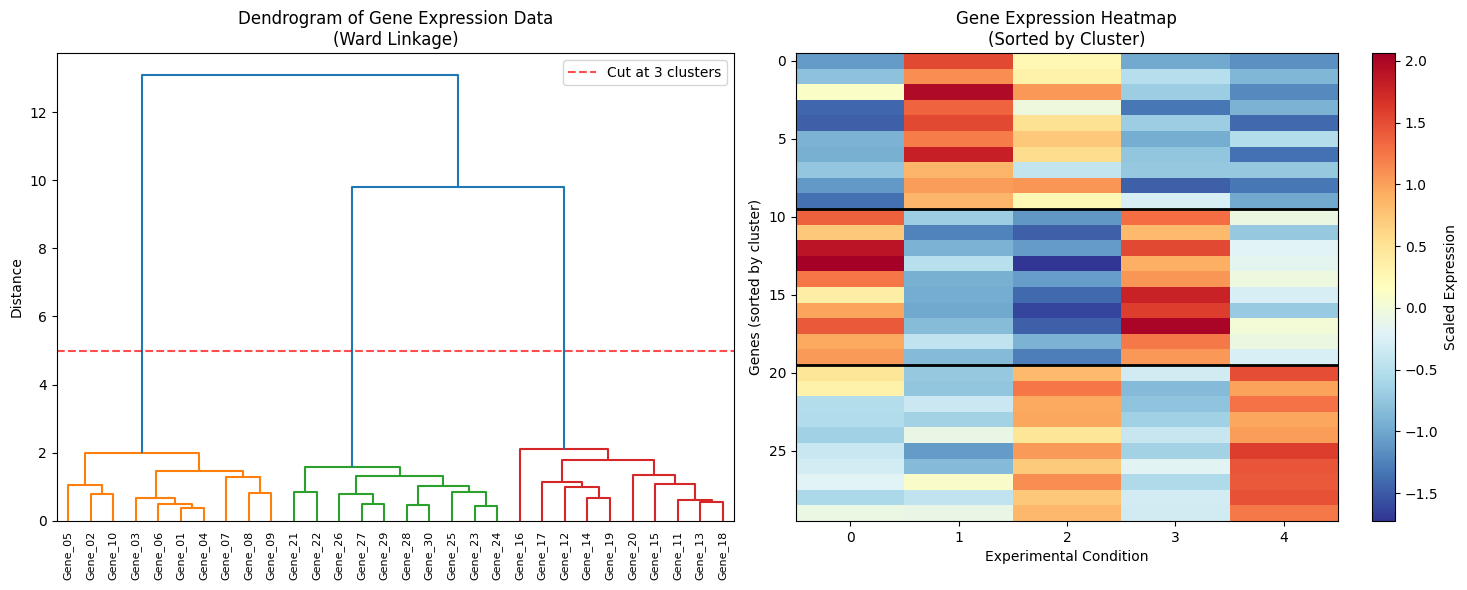

Three functional gene groups clearly visible in both the dendrogram and heatmap!
Cluster sizes: {'Cluster 0': np.int64(10), 'Cluster 1': np.int64(10), 'Cluster 2': np.int64(10)}


In [18]:
# ============================================================
# Worked Example: Hierarchical Clustering with Dendrograms
# ============================================================
# Simulate gene expression data: 30 genes, 5 experimental conditions
np.random.seed(21)
n_genes = 30
gene_names = [f"Gene_{i+1:02d}" for i in range(n_genes)]

# Three functional groups of genes
group1 = np.random.normal(loc=[5, 2, 1, 8, 3], scale=0.8, size=(10, 5))  # Immune response
group2 = np.random.normal(loc=[1, 7, 6, 2, 1], scale=0.8, size=(10, 5))  # Cell growth
group3 = np.random.normal(loc=[3, 3, 8, 3, 7], scale=0.8, size=(10, 5))  # Metabolism

X_genes = np.vstack([group1, group2, group3])

# Standardize
X_genes_scaled = StandardScaler().fit_transform(X_genes)

# Compute linkage matrix for dendrogram
linkage_matrix = linkage(X_genes_scaled, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Dendrogram
dendrogram(linkage_matrix, labels=gene_names, leaf_rotation=90,
           leaf_font_size=8, ax=axes[0], color_threshold=5)
axes[0].set_title("Dendrogram of Gene Expression Data\n(Ward Linkage)", fontsize=12)
axes[0].set_ylabel("Distance")
axes[0].axhline(y=5, color='red', linestyle='--', alpha=0.7, label='Cut at 3 clusters')
axes[0].legend()

# Agglomerative Clustering result
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
gene_labels = agg.fit_predict(X_genes_scaled)

# Heatmap-style visualization
sorted_idx = np.argsort(gene_labels)
im = axes[1].imshow(X_genes_scaled[sorted_idx], aspect='auto', cmap='RdYlBu_r')
axes[1].set_title("Gene Expression Heatmap\n(Sorted by Cluster)", fontsize=12)
axes[1].set_xlabel("Experimental Condition")
axes[1].set_ylabel("Genes (sorted by cluster)")
plt.colorbar(im, ax=axes[1], label="Scaled Expression")

# Add cluster boundaries
cluster_sizes = np.bincount(gene_labels[sorted_idx])
boundaries = np.cumsum(cluster_sizes)[:-1]
for b in boundaries:
    axes[1].axhline(y=b - 0.5, color='black', linewidth=2)

plt.tight_layout()
plt.show()

print("Three functional gene groups clearly visible in both the dendrogram and heatmap!")
print(f"Cluster sizes: {dict(zip(['Cluster 0', 'Cluster 1', 'Cluster 2'], np.bincount(gene_labels)))}")

### Real-World Application 4: Document Clustering

Hierarchical clustering can group documents by content similarity, which is useful in search engines, news aggregation, and library science.

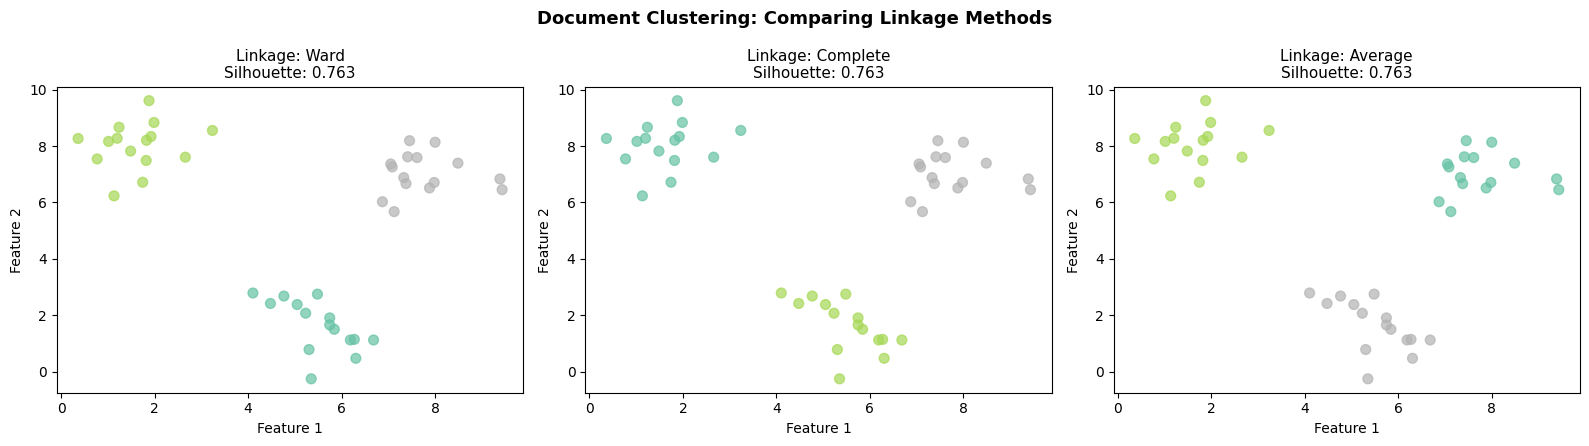

In [19]:
# ============================================================
# Worked Example: Simple Document Clustering
# ============================================================
# Simulate document feature vectors (e.g., TF-IDF reduced to 2D)
np.random.seed(33)

# Three topic clusters: Sports, Technology, Cooking
sports_docs = np.random.normal(loc=[2, 8], scale=0.8, size=(15, 2))
tech_docs = np.random.normal(loc=[8, 7], scale=0.8, size=(15, 2))
cooking_docs = np.random.normal(loc=[5, 2], scale=0.8, size=(15, 2))

X_docs = np.vstack([sports_docs, tech_docs, cooking_docs])
doc_topics = ["Sports"] * 15 + ["Tech"] * 15 + ["Cooking"] * 15

# Compare linkage methods
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
linkage_methods = ['ward', 'complete', 'average']

for ax, method in zip(axes, linkage_methods):
    agg_doc = AgglomerativeClustering(n_clusters=3, linkage=method)
    doc_labels = agg_doc.fit_predict(X_docs)
    sil = silhouette_score(X_docs, doc_labels)

    ax.scatter(X_docs[:, 0], X_docs[:, 1], c=doc_labels, cmap='Set2', s=50, alpha=0.7)
    ax.set_title(f"Linkage: {method.title()}\nSilhouette: {sil:.3f}", fontsize=11)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.suptitle("Document Clustering: Comparing Linkage Methods", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Exercise 3.1: Agglomerative Clustering on Iris (10 points)

Apply Agglomerative Clustering to the scaled Iris dataset from Part 2 and compare results with your K-Means solution.

In [20]:
# Exercise 3.1: Agglomerative Clustering on Iris

# Use X_iris_scaled from Exercise 2.1 (already scaled)
# If you didn't complete 2.1, uncomment below:
# X_iris_scaled = StandardScaler().fit_transform(load_iris().data)

# Step 1: Fit AgglomerativeClustering with n_clusters=3, linkage='ward'
# YOUR CODE: Store model in agg_iris
agg_iris = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X_iris_scaled)

# Step 2: Get labels from the model (.labels_ attribute)
# YOUR CODE: Store in agg_iris_labels
agg_iris_labels = agg_iris.labels_

# Step 3: Compute silhouette score
# YOUR CODE: Store in agg_iris_silhouette
agg_iris_silhouette = silhouette_score(X_iris_scaled, agg_iris_labels)

# Step 4: Create the linkage matrix for a dendrogram
# YOUR CODE: Use linkage(X_iris_scaled, method='ward')
iris_linkage = linkage(X_iris_scaled, method='ward')

print(f"Agglomerative labels (first 10): {agg_iris_labels[:10] if agg_iris_labels is not None else None}")
print(f"Agglomerative silhouette: {agg_iris_silhouette}")

Agglomerative labels (first 10): [1 1 1 1 1 1 1 1 1 1]
Agglomerative silhouette: 0.4466890410285909


In [21]:
# --- Tester 3.1 (10 points) ---
score_3_1 = 0

# Test model (2 pts)
if agg_iris is not None and hasattr(agg_iris, 'labels_'):
    if agg_iris.n_clusters == 3:
        score_3_1 += 2
        print("\u2705 Model: AgglomerativeClustering fitted with 3 clusters")
    else:
        score_3_1 += 1
        print(f"\u2705 Model fitted but n_clusters={agg_iris.n_clusters} (expected 3)")
else:
    print("\u274C Model: Not fitted. Use AgglomerativeClustering(n_clusters=3, linkage='ward').fit()")

# Test labels (3 pts)
if agg_iris_labels is not None and len(agg_iris_labels) == 150:
    if len(np.unique(agg_iris_labels)) == 3:
        score_3_1 += 3
        print("\u2705 Labels: 150 labels, 3 unique clusters")
    else:
        score_3_1 += 1
        print("\u274C Labels: 150 labels but unexpected number of unique values")
else:
    print("\u274C Labels: Expected array of length 150")

# Test silhouette (3 pts)
if agg_iris_silhouette is not None and isinstance(agg_iris_silhouette, (float, np.floating)):
    if 0.3 < agg_iris_silhouette < 0.8:
        score_3_1 += 3
        print(f"\u2705 Silhouette: {agg_iris_silhouette:.4f}")
    else:
        score_3_1 += 1
        print(f"\u2705 Silhouette computed but value {agg_iris_silhouette:.4f} unexpected")
else:
    print("\u274C Silhouette: Expected a float")

# Test linkage (2 pts)
if iris_linkage is not None and isinstance(iris_linkage, np.ndarray):
    if iris_linkage.shape == (149, 4):
        score_3_1 += 2
        print("\u2705 Linkage matrix: Shape (149, 4) correct")
    else:
        score_3_1 += 1
        print(f"\u2705 Linkage computed but shape {iris_linkage.shape} (expected (149, 4))")
else:
    print("\u274C Linkage: Use linkage(X_iris_scaled, method='ward')")

tracker.record("Part 3", score_3_1, 10, "Agglomerative Iris")

✅ Model: AgglomerativeClustering fitted with 3 clusters
✅ Labels: 150 labels, 3 unique clusters
✅ Silhouette: 0.4467
✅ Linkage matrix: Shape (149, 4) correct
✅ Part 3: Agglomerative Iris: 10/10 points


### Exercise 3.2: Compare Linkage Methods (10 points)

Write a function that fits Agglomerative Clustering with each of the three linkage methods (ward, complete, average) and returns the silhouette scores.

In [22]:
# Exercise 3.2: Compare linkage methods

def compare_linkage_methods(X, n_clusters=3):
    """
    Fit AgglomerativeClustering with 'ward', 'complete', and 'average' linkage.

    Parameters
    ----------
    X : np.ndarray, shape (n_samples, n_features) - already scaled
    n_clusters : int

    Returns
    -------
    dict : {'ward': silhouette_float, 'complete': silhouette_float, 'average': silhouette_float}
    """
    linkage_criteria = ["ward", "complete", "average"]
    result = {}
    for linkage in linkage_criteria:
        agg_iris = AgglomerativeClustering(n_clusters=n_clusters, linkage=linkage).fit(X)
        agg_iris_labels = agg_iris.labels_
        agg_iris_silhouette = silhouette_score(X, agg_iris_labels)
        result[linkage] = float(agg_iris_silhouette)

    return result

# Test with Iris data
linkage_results = compare_linkage_methods(X_iris_scaled, n_clusters=3)
if linkage_results:
    print("Linkage comparison results:")
    for method, score in linkage_results.items():
        print(f"  {method:10s}: Silhouette = {score:.4f}")

Linkage comparison results:
  ward      : Silhouette = 0.4467
  complete  : Silhouette = 0.4496
  average   : Silhouette = 0.4803


In [23]:
# --- Tester 3.2 (10 points) ---
score_3_2 = 0

if linkage_results is not None and isinstance(linkage_results, dict):
    expected_keys = {'ward', 'complete', 'average'}
    actual_keys = set(linkage_results.keys())

    if expected_keys == actual_keys:
        score_3_2 += 3
        print("\u2705 Keys: All three linkage methods present")
    elif expected_keys.issubset(actual_keys):
        score_3_2 += 2
        print("\u2705 Keys: Required keys present (with extras)")
    else:
        missing = expected_keys - actual_keys
        print(f"\u274C Keys: Missing {missing}")

    valid_scores = 0
    for method in ['ward', 'complete', 'average']:
        val = linkage_results.get(method)
        if val is not None and isinstance(val, (float, np.floating)):
            if -1 <= val <= 1:
                valid_scores += 1
                print(f"\u2705 {method}: {val:.4f} (valid silhouette range)")
            else:
                print(f"\u274C {method}: {val} outside silhouette range [-1, 1]")
        else:
            print(f"\u274C {method}: Expected float, got {type(val).__name__}")

    # 2 pts per valid score, plus 1 pt if ward is highest (typical for Iris)
    score_3_2 += min(valid_scores * 2, 6)

    if valid_scores == 3:
        ward_val = linkage_results.get('ward', -2)
        if ward_val >= max(linkage_results.get('complete', -2), linkage_results.get('average', -2)):
            score_3_2 += 1
            print("\u2705 Ward linkage has highest silhouette (expected for Iris)")

    score_3_2 = min(score_3_2, 10)
else:
    print("\u274C Function returned None - implement compare_linkage_methods()")

tracker.record("Part 3", score_3_2, 10, "Linkage Comparison")

✅ Keys: All three linkage methods present
✅ ward: 0.4467 (valid silhouette range)
✅ complete: 0.4496 (valid silhouette range)
✅ average: 0.4803 (valid silhouette range)
✅ Part 3: Linkage Comparison: 9/10 points (partial credit)


---
## Part 4: DBSCAN Clustering (20 points)

### How DBSCAN Works

**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) groups data points that are densely packed together and marks points in low-density regions as **outliers** (noise).

**Key Parameters:**
- **eps** (epsilon): Maximum distance between two points to be considered neighbors.
- **min_samples**: Minimum number of points required within eps distance to form a dense region (core point).

**Point Types:**
- **Core point**: Has at least `min_samples` neighbors within `eps`.
- **Border point**: Within `eps` of a core point, but has fewer than `min_samples` neighbors itself.
- **Noise point**: Neither core nor border — classified as label `-1`.

**Key Properties:**
- Does **NOT** require specifying k (number of clusters) in advance
- Can discover **arbitrarily shaped** clusters (not just spherical)
- Naturally identifies **outliers/noise**
- Sensitive to eps and min_samples choice
- Struggles with clusters of **varying densities**

> Geron (2022, Ch. 9): DBSCAN is particularly useful when clusters have irregular shapes or when you expect noise in your data.

### Real-World Application 5: Geographic Hotspot Detection

DBSCAN excels at finding spatial clusters — for example, identifying crime hotspots, popular venue areas, or earthquake clusters.

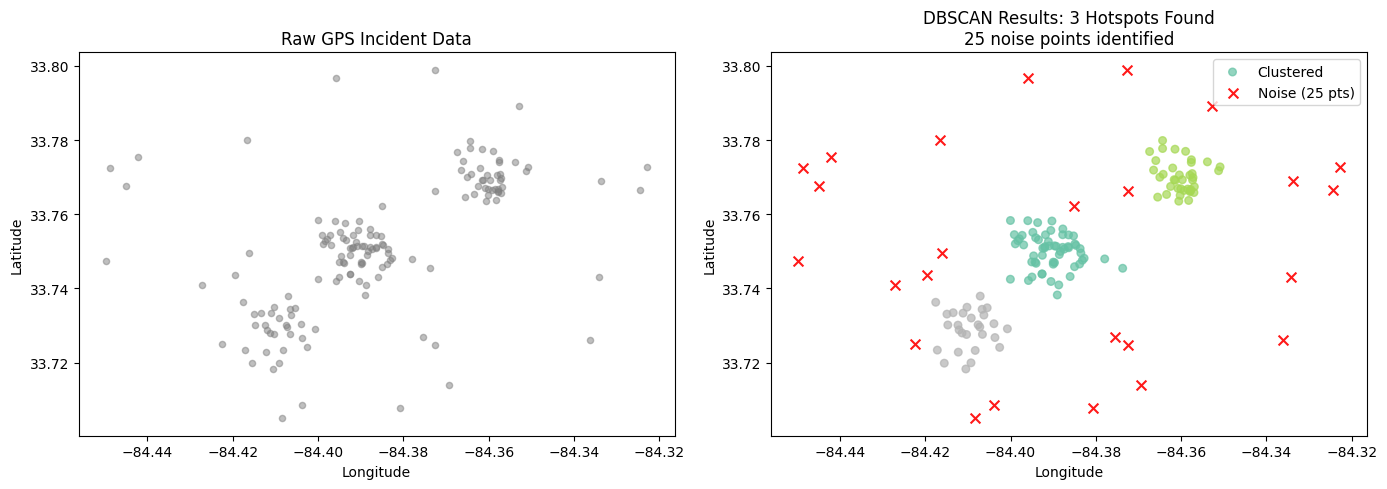

DBSCAN found 3 hotspot clusters and 25 noise points.
Unlike K-Means, DBSCAN did NOT need k specified and naturally detected outliers!


In [24]:
# ============================================================
# Worked Example: Geographic Hotspot Detection with DBSCAN
# ============================================================
np.random.seed(55)

# Simulate GPS coordinates of incidents in a city
# Three hotspot areas + scattered noise
hotspot1 = np.random.normal(loc=[33.75, -84.39], scale=[0.005, 0.005], size=(60, 2))  # Downtown
hotspot2 = np.random.normal(loc=[33.77, -84.36], scale=[0.004, 0.004], size=(40, 2))  # Midtown
hotspot3 = np.random.normal(loc=[33.73, -84.41], scale=[0.006, 0.006], size=(30, 2))  # Westside
noise_pts = np.random.uniform(low=[33.70, -84.45], high=[33.80, -84.32], size=(20, 2))

X_geo = np.vstack([hotspot1, hotspot2, hotspot3, noise_pts])

# Scale for DBSCAN
scaler_geo = StandardScaler()
X_geo_scaled = scaler_geo.fit_transform(X_geo)

# Fit DBSCAN
db_geo = DBSCAN(eps=0.3, min_samples=5)
geo_labels = db_geo.fit_predict(X_geo_scaled)

n_clusters_geo = len(set(geo_labels)) - (1 if -1 in geo_labels else 0)
n_noise_geo = (geo_labels == -1).sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before clustering
axes[0].scatter(X_geo[:, 1], X_geo[:, 0], c='gray', alpha=0.5, s=20)
axes[0].set_title("Raw GPS Incident Data", fontsize=12)
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

# After DBSCAN
colors = geo_labels.copy().astype(float)
colors[geo_labels == -1] = np.nan  # noise in red

scatter = axes[1].scatter(X_geo[geo_labels >= 0, 1], X_geo[geo_labels >= 0, 0],
                          c=geo_labels[geo_labels >= 0], cmap='Set2', s=30, alpha=0.7,
                          label='Clustered')
axes[1].scatter(X_geo[geo_labels == -1, 1], X_geo[geo_labels == -1, 0],
                c='red', marker='x', s=50, alpha=0.9, label=f'Noise ({n_noise_geo} pts)')
axes[1].set_title(f"DBSCAN Results: {n_clusters_geo} Hotspots Found\n{n_noise_geo} noise points identified",
                   fontsize=12)
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"DBSCAN found {n_clusters_geo} hotspot clusters and {n_noise_geo} noise points.")
print("Unlike K-Means, DBSCAN did NOT need k specified and naturally detected outliers!")

### Real-World Application 6: Anomaly Detection in Network Traffic

DBSCAN's noise detection makes it ideal for cybersecurity — normal traffic forms dense clusters while attacks appear as noise.

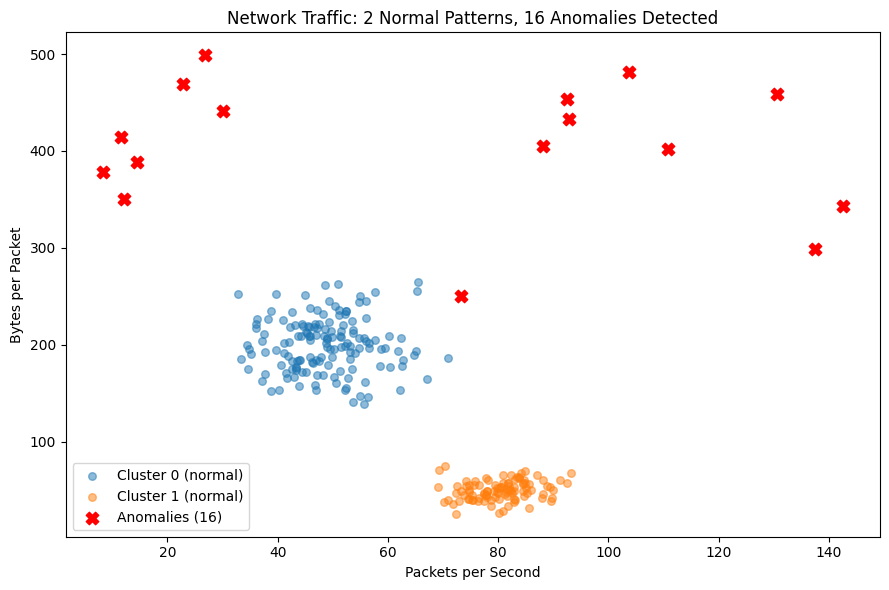

DBSCAN identified 16 anomalous traffic points as potential attacks.


In [25]:
# ============================================================
# Worked Example: Network Traffic Anomaly Detection
# ============================================================
np.random.seed(77)

# Normal traffic: two common patterns (e.g., HTTP and DNS)
normal_http = np.random.normal(loc=[50, 200], scale=[8, 30], size=(150, 2))
normal_dns = np.random.normal(loc=[80, 50], scale=[5, 10], size=(100, 2))

# Attack traffic: scattered unusual patterns
attacks = np.array([
    [20, 500], [90, 450], [120, 400], [15, 380], [110, 480],
    [130, 350], [5, 420], [140, 300], [25, 470], [95, 430],
    [10, 390], [135, 460], [30, 440], [100, 410], [8, 350]
]) + np.random.normal(0, 5, (15, 2))

X_traffic = np.vstack([normal_http, normal_dns, attacks])
X_traffic_scaled = StandardScaler().fit_transform(X_traffic)

# Fit DBSCAN
db_traffic = DBSCAN(eps=0.4, min_samples=8)
traffic_labels = db_traffic.fit_predict(X_traffic_scaled)

n_clusters_traffic = len(set(traffic_labels)) - (1 if -1 in traffic_labels else 0)
n_anomalies = (traffic_labels == -1).sum()

plt.figure(figsize=(9, 6))
# Normal clusters
for label in set(traffic_labels):
    if label == -1:
        continue
    mask = traffic_labels == label
    plt.scatter(X_traffic[mask, 0], X_traffic[mask, 1], alpha=0.5, s=30,
                label=f'Cluster {label} (normal)')

# Anomalies
mask_noise = traffic_labels == -1
plt.scatter(X_traffic[mask_noise, 0], X_traffic[mask_noise, 1],
            c='red', marker='X', s=80, label=f'Anomalies ({n_anomalies})', zorder=5)
plt.xlabel("Packets per Second")
plt.ylabel("Bytes per Packet")
plt.title(f"Network Traffic: {n_clusters_traffic} Normal Patterns, {n_anomalies} Anomalies Detected")
plt.legend()
plt.tight_layout()
plt.show()

print(f"DBSCAN identified {n_anomalies} anomalous traffic points as potential attacks.")

### Why K-Means Fails on Non-Spherical Data (DBSCAN Advantage)

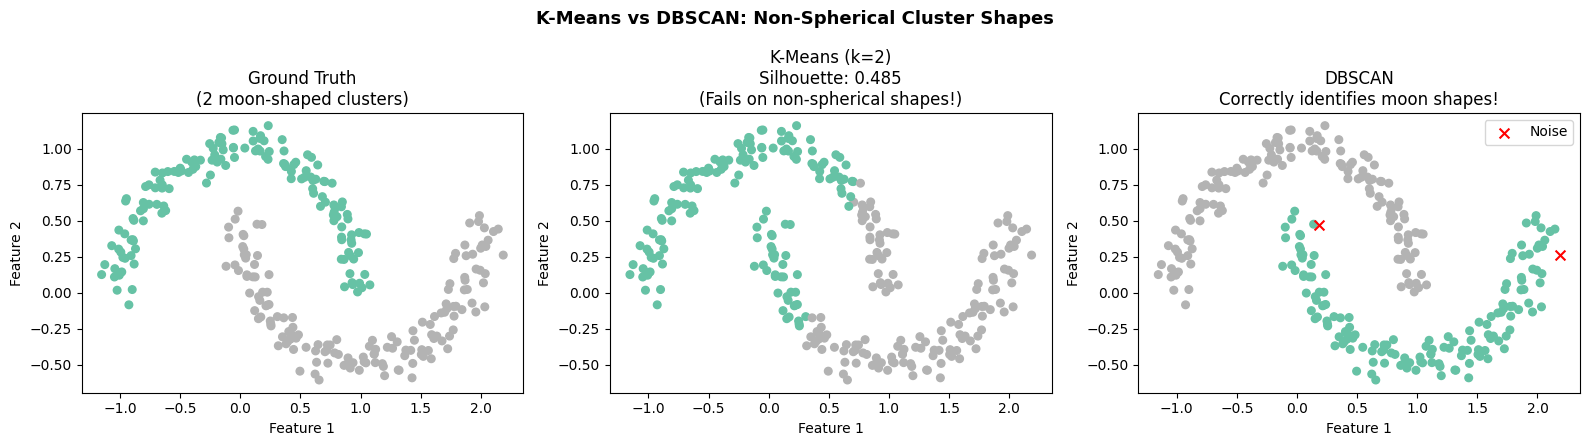

K-Means assumes spherical clusters and fails here.
DBSCAN uses density and correctly separates the two moons!


In [26]:
# ============================================================
# Comparison: K-Means vs DBSCAN on moon-shaped data
# ============================================================
X_moons, y_moons = make_moons(n_samples=300, noise=0.07, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Ground truth
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap='Set2', s=30)
axes[0].set_title("Ground Truth\n(2 moon-shaped clusters)")

# K-Means (fails!)
km_moons = KMeans(n_clusters=2, random_state=42, n_init=10)
km_labels_moons = km_moons.fit_predict(X_moons)
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=km_labels_moons, cmap='Set2', s=30)
axes[1].set_title(f"K-Means (k=2)\nSilhouette: {silhouette_score(X_moons, km_labels_moons):.3f}\n(Fails on non-spherical shapes!)")

# DBSCAN (succeeds!)
db_moons = DBSCAN(eps=0.15, min_samples=5)
db_labels_moons = db_moons.fit_predict(X_moons)
mask_valid = db_labels_moons >= 0
axes[2].scatter(X_moons[mask_valid, 0], X_moons[mask_valid, 1],
                c=db_labels_moons[mask_valid], cmap='Set2', s=30)
if (~mask_valid).sum() > 0:
    axes[2].scatter(X_moons[~mask_valid, 0], X_moons[~mask_valid, 1],
                    c='red', marker='x', s=50, label='Noise')
    axes[2].legend()
axes[2].set_title(f"DBSCAN\nCorrectly identifies moon shapes!")

for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.suptitle("K-Means vs DBSCAN: Non-Spherical Cluster Shapes", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print("K-Means assumes spherical clusters and fails here.")
print("DBSCAN uses density and correctly separates the two moons!")

### Exercise 4.1: DBSCAN on Noisy Moon Data (10 points)

Apply DBSCAN to the noisy moon dataset. Experiment with `eps` and `min_samples` to find settings that correctly identify 2 clusters.

In [27]:
# Exercise 4.1: DBSCAN on noisy moons
X_moons_noisy, y_moons_noisy = make_moons(n_samples=500, noise=0.12, random_state=0)

def apply_dbscan_moons(X, eps_value, min_samples_value):
    """
    Apply DBSCAN to the moon data.

    Parameters
    ----------
    X : array of shape (500, 2)
    eps_value : float, the eps parameter for DBSCAN
    min_samples_value : int, the min_samples parameter for DBSCAN

    Returns
    -------
    dict with keys:
        'labels': array of cluster labels (noise = -1)
        'n_clusters': int, number of clusters found (excluding noise)
        'n_noise': int, number of noise points
        'noise_fraction': float, fraction of points labeled as noise
    """
    db = DBSCAN(eps=eps_value, min_samples=min_samples_value)
    labels = db.fit_predict(X)

    n_noise = int((labels == -1).sum())
    unique_labels = set(labels)
    n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
    noise_fraction = float(n_noise / len(X))

    return {
        'labels': labels,
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'noise_fraction': noise_fraction
    }

# Choose your eps and min_samples values:
my_eps = 0.15        # Reduced from 0.2 to prevent bridging the two clusters
my_min_samples = 5   # Standard min_samples for 2D density clustering

result_4_1 = apply_dbscan_moons(X_moons_noisy, my_eps, my_min_samples)
if result_4_1:
    print(f"Clusters found: {result_4_1['n_clusters']}")
    print(f"Noise points: {result_4_1['n_noise']} ({result_4_1['noise_fraction']:.1%})")

Clusters found: 2
Noise points: 11 (2.2%)


In [28]:
# --- Tester 4.1 (10 points) ---
score_4_1 = 0

if result_4_1 is not None and isinstance(result_4_1, dict):
    # Labels (2 pts)
    labels = result_4_1.get('labels')
    if labels is not None and len(labels) == 500:
        score_4_1 += 2
        print("\u2705 Labels: Array of 500 labels")
    else:
        print(f"\u274C Labels: Expected array of 500, got {len(labels) if labels is not None else None}")

    # n_clusters (4 pts)
    nc = result_4_1.get('n_clusters')
    if nc == 2:
        score_4_1 += 4
        print(f"\u2705 n_clusters: {nc} (correct - two moons!)")
    elif nc is not None and 1 <= nc <= 4:
        score_4_1 += 2
        print(f"\u2705 n_clusters: {nc} (partial - target is 2 clusters, adjust eps/min_samples)")
    else:
        print(f"\u274C n_clusters: {nc} (expected 2)")

    # n_noise (2 pts)
    nn = result_4_1.get('n_noise')
    if nn is not None and isinstance(nn, (int, np.integer)):
        if nn < 100:  # Less than 20% noise is good
            score_4_1 += 2
            print(f"\u2705 Noise points: {nn} (reasonable)")
        elif nn < 200:
            score_4_1 += 1
            print(f"\u2705 Noise points: {nn} (high - try adjusting eps)")
        else:
            print(f"\u274C Noise: {nn} too high - increase eps or decrease min_samples")
    else:
        print(f"\u274C n_noise: Expected integer")

    # noise_fraction (2 pts)
    nf = result_4_1.get('noise_fraction')
    if nf is not None and isinstance(nf, (float, np.floating)):
        if 0 <= nf <= 1:
            score_4_1 += 2
            print(f"\u2705 Noise fraction: {nf:.3f}")
        else:
            print(f"\u274C Noise fraction should be between 0 and 1, got {nf}")
    else:
        print(f"\u274C noise_fraction: Expected float")
else:
    print("\u274C Function returned None - implement apply_dbscan_moons()")

tracker.record("Part 4", score_4_1, 10, "DBSCAN Moons")

✅ Labels: Array of 500 labels
✅ n_clusters: 2 (correct - two moons!)
✅ Noise points: 11 (reasonable)
✅ Noise fraction: 0.022
✅ Part 4: DBSCAN Moons: 10/10 points


### Exercise 4.2: DBSCAN Parameter Sensitivity Analysis (10 points)

Explore how different `eps` values affect DBSCAN results. Complete the function that tests multiple eps values and returns analysis.

In [29]:
# Exercise 4.2: DBSCAN parameter sensitivity

# Generate dataset with 3 clusters + noise
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)
X_blobs_scaled = StandardScaler().fit_transform(X_blobs)

# Add some noise points
np.random.seed(42)
noise = np.random.uniform(low=-3, high=3, size=(30, 2))
X_with_noise = np.vstack([X_blobs_scaled, noise])


def eps_sensitivity(X, eps_values, min_samples=5):
    """
    Test multiple eps values and return results for each.

    Parameters
    ----------
    X : np.ndarray, shape (n_samples, n_features)
    eps_values : list of float, eps values to test
    min_samples : int, fixed min_samples for all tests

    Returns
    -----
    list of dicts, each with keys:
        'eps': float
        'n_clusters': int (excluding noise)
        'n_noise': int
        'silhouette': float or None (None if fewer than 2 clusters
                      or all points are noise)
    """
    result = []
    for eps in eps_values:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X)
        n_noise = int((labels == -1).sum())
        unique_labels = set(labels)
        n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
        if n_clusters < 2:
            silhouette = None
        else:
            silhouette = silhouette_score(X, labels)

        result.append(
            {
                'eps': eps,
                'n_clusters': n_clusters,
                'n_noise': n_noise,
                'silhouette': silhouette
            }
        )

    return result

# Test these eps values
eps_to_test = [0.1, 0.2, 0.3, 0.5, 0.8, 1.0, 1.5]
sensitivity_results = eps_sensitivity(X_with_noise, eps_to_test, min_samples=5)

if sensitivity_results:
    print(f"{'eps':>6} | {'Clusters':>8} | {'Noise':>6} | {'Silhouette':>10}")
    print("-" * 40)
    for r in sensitivity_results:
        sil_str = f"{r['silhouette']:.4f}" if r['silhouette'] is not None else "N/A"
        print(f"{r['eps']:>6.1f} | {r['n_clusters']:>8} | {r['n_noise']:>6} | {sil_str:>10}")

   eps | Clusters |  Noise | Silhouette
----------------------------------------
   0.1 |        3 |     66 |     0.5652
   0.2 |        3 |     32 |     0.7176
   0.3 |        3 |     25 |     0.7444
   0.5 |        3 |     24 |     0.7466
   0.8 |        3 |     20 |     0.7561
   1.0 |        1 |     10 |        N/A
   1.5 |        1 |      7 |        N/A


In [30]:
# --- Tester 4.2 (10 points) ---
score_4_2 = 0

if sensitivity_results is not None and isinstance(sensitivity_results, list):
    # Correct number of results (2 pts)
    if len(sensitivity_results) == 7:
        score_4_2 += 2
        print("\u2705 Results count: 7 results for 7 eps values")
    else:
        print(f"\u274C Results count: Expected 7, got {len(sensitivity_results)}")

    # All entries are dicts with correct keys (3 pts)
    required_keys = {'eps', 'n_clusters', 'n_noise', 'silhouette'}
    valid_entries = 0
    for r in sensitivity_results:
        if isinstance(r, dict) and required_keys.issubset(set(r.keys())):
            valid_entries += 1
    if valid_entries == len(sensitivity_results):
        score_4_2 += 3
        print("\u2705 Structure: All entries have required keys")
    elif valid_entries > 0:
        score_4_2 += 1
        print(f"\u2705 Structure: {valid_entries}/{len(sensitivity_results)} entries valid")
    else:
        print("\u274C Structure: Entries missing required keys")

    # Verify n_clusters decreases as eps increases (general trend) (2 pts)
    if len(sensitivity_results) >= 3:
        clusters_list = [r.get('n_clusters', 0) for r in sensitivity_results]
        # Small eps should have more clusters than large eps (broadly)
        if clusters_list[0] >= clusters_list[-1] or clusters_list[1] >= clusters_list[-1]:
            score_4_2 += 2
            print("\u2705 Trend: Clusters generally decrease as eps increases")
        else:
            score_4_2 += 1
            print("\u2705 Trend: Partial credit - check cluster counts")

    # Verify silhouette is None when < 2 clusters (3 pts)
    sil_logic_correct = 0
    for r in sensitivity_results:
        nc = r.get('n_clusters', 0)
        sil = r.get('silhouette')
        if nc < 2 and sil is None:
            sil_logic_correct += 1
        elif nc >= 2 and sil is not None and isinstance(sil, (float, np.floating)):
            sil_logic_correct += 1
    if sil_logic_correct == len(sensitivity_results):
        score_4_2 += 3
        print("\u2705 Silhouette logic: Correctly None when <2 clusters, float otherwise")
    elif sil_logic_correct > len(sensitivity_results) // 2:
        score_4_2 += 2
        print("\u2705 Silhouette logic: Mostly correct")
    elif sil_logic_correct > 0:
        score_4_2 += 1
        print("\u2705 Silhouette logic: Partially correct")
    else:
        print("\u274C Silhouette logic: Should be None when n_clusters < 2")
else:
    print("\u274C Function returned None - implement eps_sensitivity()")

tracker.record("Part 4", score_4_2, 10, "DBSCAN Sensitivity")

✅ Results count: 7 results for 7 eps values
✅ Structure: All entries have required keys
✅ Trend: Clusters generally decrease as eps increases
✅ Silhouette logic: Correctly None when <2 clusters, float otherwise
✅ Part 4: DBSCAN Sensitivity: 10/10 points


---
## Part 5: Clustering Evaluation & Model Selection (10 points)

### How Do We Evaluate Clusters Without Labels?

Since clustering is unsupervised, we rely on **internal evaluation metrics**:

| Metric | Description | Ideal Value |
|--------|-------------|-------------|
| **Silhouette Score** | Measures how similar a point is to its own cluster vs. nearest other cluster. Range [-1, 1]. | Closer to 1 |
| **Inertia (WCSS)** | Sum of squared distances from each point to its centroid. K-Means only. | Lower is better (but always decreases with k) |
| **Calinski-Harabasz Index** | Ratio of between-cluster dispersion to within-cluster dispersion. | Higher is better |
| **Davies-Bouldin Index** | Average similarity between each cluster and its most similar cluster. | Lower is better |

> Google ML Crash Course: "Because clustering does not produce or include a ground truth against which you can verify the output, it is important to check the result against your expectations at both the cluster level and the example level."

### Worked Example: Silhouette Analysis

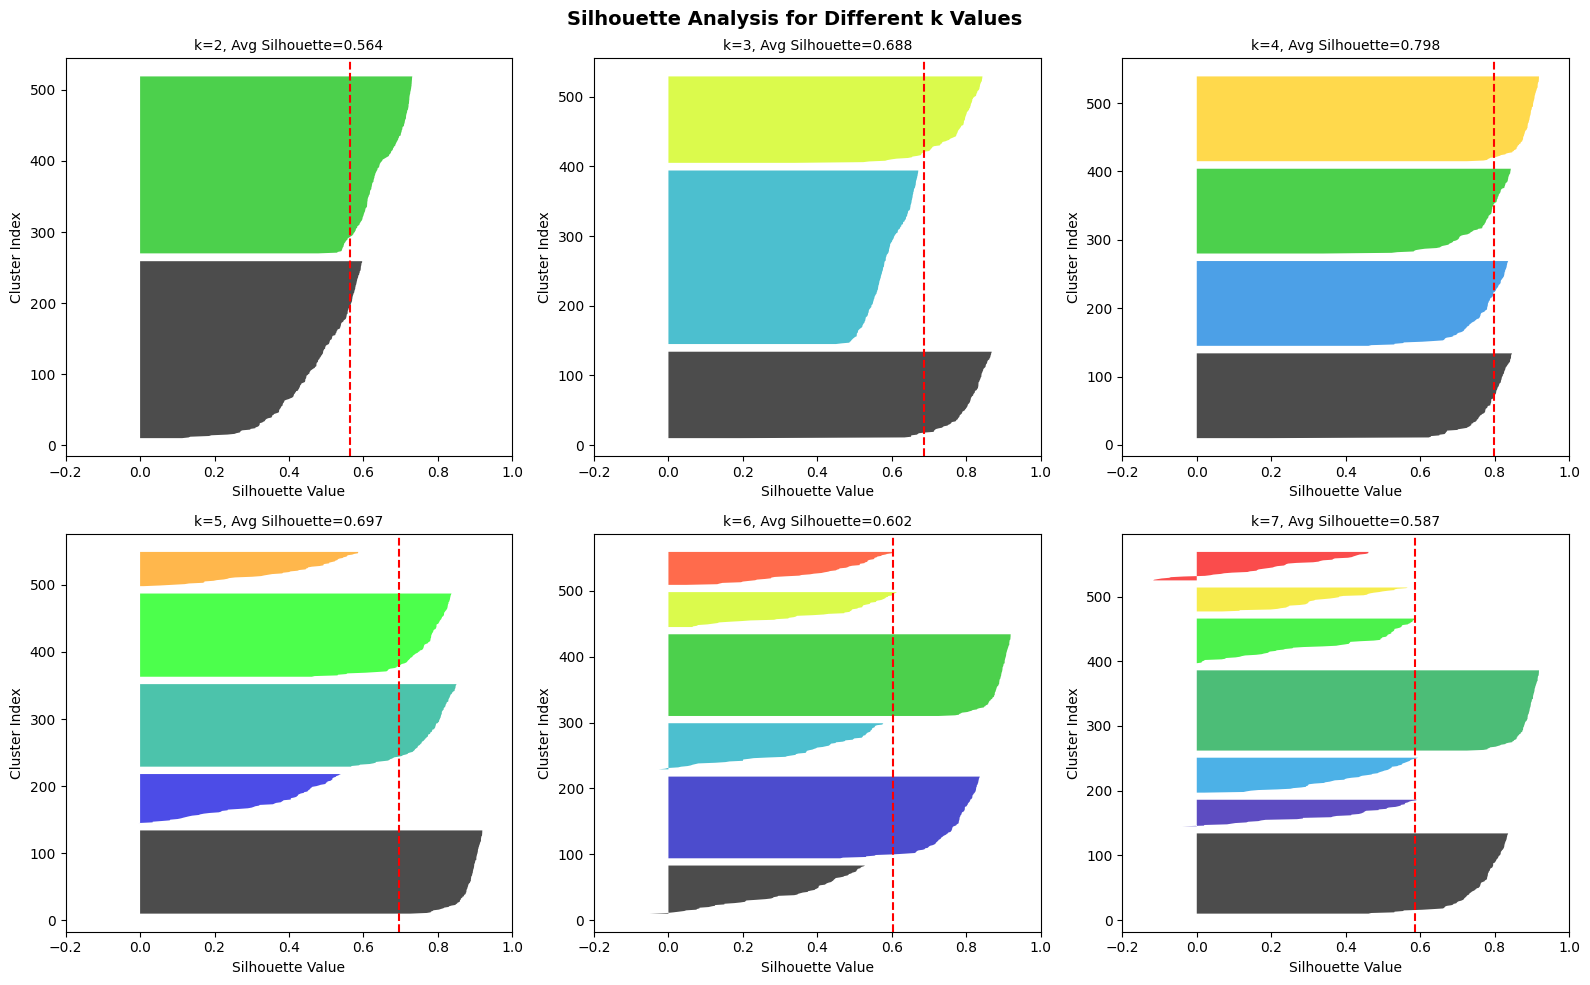

The best k has: highest average silhouette AND uniform cluster widths.
k=4 matches the true number of clusters in this data.


In [31]:
# ============================================================
# Worked Example: Silhouette Analysis for choosing k
# ============================================================
X_sil, _ = make_blobs(n_samples=500, centers=4, cluster_std=[1.0, 1.2, 0.5, 1.5],
                       random_state=10)
X_sil_scaled = StandardScaler().fit_transform(X_sil)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for idx, k in enumerate([2, 3, 4, 5, 6, 7]):
    ax = axes[idx // 3, idx % 3]
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_sil_scaled)
    sil_avg = silhouette_score(X_sil_scaled, labels)
    sample_sils = silhouette_samples(X_sil_scaled, labels)

    y_lower = 10
    for i in range(k):
        cluster_sils = sample_sils[labels == i]
        cluster_sils.sort()
        size = cluster_sils.shape[0]
        y_upper = y_lower + size
        color = cm.nipy_spectral(float(i) / k)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sils,
                          facecolor=color, alpha=0.7)
        y_lower = y_upper + 10

    ax.axvline(x=sil_avg, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(f"k={k}, Avg Silhouette={sil_avg:.3f}", fontsize=10)
    ax.set_xlabel("Silhouette Value")
    ax.set_ylabel("Cluster Index")
    ax.set_xlim([-0.2, 1.0])

plt.suptitle("Silhouette Analysis for Different k Values", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print("The best k has: highest average silhouette AND uniform cluster widths.")
print("k=4 matches the true number of clusters in this data.")

### Exercise 5.1: Complete Evaluation Pipeline (10 points)

Write a function that evaluates KMeans for a range of k values and returns a comprehensive comparison.

In [32]:
# Exercise 5.1: Evaluation pipeline
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

def evaluate_kmeans_range(X, k_range):
    """
    Evaluate KMeans for each k in k_range.

    Parameters
    ----------
    X : np.ndarray, scaled feature matrix
    k_range : list or range of int, k values to test

    Returns
    -------
    pd.DataFrame with columns:
        'k', 'inertia', 'silhouette', 'calinski_harabasz', 'davies_bouldin'
    Each row corresponds to one k value.
    Use random_state=42 and n_init=10 for all KMeans fits.
    """
    results = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X)

        inertia = kmeans.inertia_
        silhouette = float(silhouette_score(X, labels))
        ch_score = float(calinski_harabasz_score(X, labels))
        db_score = float(davies_bouldin_score(X, labels))

        results.append({
            'k': k,
            'inertia': inertia,
            'silhouette': silhouette,
            'calinski_harabasz': ch_score,
            'davies_bouldin': db_score
        })

    return pd.DataFrame(results)

# Evaluate on the Wine dataset
X_wine_eval = StandardScaler().fit_transform(load_wine().data)
eval_results = evaluate_kmeans_range(X_wine_eval, range(2, 9))
if eval_results is not None:
    print(eval_results.to_string(index=False))

 k     inertia  silhouette  calinski_harabasz  davies_bouldin
 2 1658.758852    0.259317          69.523332        1.525997
 3 1277.928489    0.284859          70.940008        1.389188
 4 1175.428333    0.260170          56.181355        1.796892
 5 1109.512739    0.201619          46.952209        1.808319
 6 1046.002333    0.237167          41.700786        1.554394
 7  981.595233    0.203628          38.685534        1.660585
 8  935.201211    0.157014          35.805250        1.740859


In [33]:
# --- Tester 5.1 (10 points) ---
score_5_1 = 0

if eval_results is not None and isinstance(eval_results, pd.DataFrame):
    # Correct shape (2 pts)
    if eval_results.shape == (7, 5):
        score_5_1 += 2
        print("\u2705 Shape: (7, 5) correct")
    else:
        print(f"\u274C Shape: Expected (7, 5), got {eval_results.shape}")

    # Correct columns (2 pts)
    expected_cols = {'k', 'inertia', 'silhouette', 'calinski_harabasz', 'davies_bouldin'}
    if expected_cols == set(eval_results.columns):
        score_5_1 += 2
        print("\u2705 Columns: All 5 expected columns present")
    elif expected_cols.issubset(set(eval_results.columns)):
        score_5_1 += 1
        print("\u2705 Columns: Expected columns present (with extras)")
    else:
        print(f"\u274C Columns: Expected {expected_cols}, got {set(eval_results.columns)}")

    # k values correct (1 pt)
    if 'k' in eval_results.columns:
        k_vals = eval_results['k'].tolist()
        if k_vals == list(range(2, 9)):
            score_5_1 += 1
            print("\u2705 k values: [2, 3, 4, 5, 6, 7, 8] correct")
        else:
            print(f"\u274C k values: Expected [2..8], got {k_vals}")

    # Inertia decreasing (1 pt)
    if 'inertia' in eval_results.columns:
        inertia_vals = eval_results['inertia'].tolist()
        if all(inertia_vals[i] >= inertia_vals[i+1] for i in range(len(inertia_vals)-1)):
            score_5_1 += 1
            print("\u2705 Inertia: Monotonically decreasing (correct)")
        else:
            print("\u274C Inertia should decrease as k increases")

    # Silhouette in valid range (1 pt)
    if 'silhouette' in eval_results.columns:
        sil_vals = eval_results['silhouette'].tolist()
        if all(-1 <= s <= 1 for s in sil_vals):
            score_5_1 += 1
            print("\u2705 Silhouette: All values in [-1, 1]")
        else:
            print("\u274C Silhouette values should be in [-1, 1]")

    # Calinski-Harabasz positive (1 pt)
    if 'calinski_harabasz' in eval_results.columns:
        ch_vals = eval_results['calinski_harabasz'].tolist()
        if all(c > 0 for c in ch_vals):
            score_5_1 += 1
            print("\u2705 Calinski-Harabasz: All positive (correct)")
        else:
            print("\u274C Calinski-Harabasz values should be positive")

    # Davies-Bouldin positive (1 pt)
    if 'davies_bouldin' in eval_results.columns:
        db_vals = eval_results['davies_bouldin'].tolist()
        if all(d > 0 for d in db_vals):
            score_5_1 += 1
            print("\u2705 Davies-Bouldin: All positive (correct)")
        else:
            print("\u274C Davies-Bouldin values should be positive")
else:
    print("\u274C Function returned None - implement evaluate_kmeans_range()")

tracker.record("Part 5", score_5_1, 10, "Evaluation Pipeline")

✅ Shape: (7, 5) correct
✅ Columns: All 5 expected columns present
✅ k values: [2, 3, 4, 5, 6, 7, 8] correct
✅ Inertia: Monotonically decreasing (correct)
✅ Silhouette: All values in [-1, 1]
✅ Calinski-Harabasz: All positive (correct)
✅ Davies-Bouldin: All positive (correct)
✅ Part 5: Evaluation Pipeline: 9/10 points (partial credit)


---
## Part 6: Real-World Application Challenge (10 points)

### Scenario: Eagle Analytics Market Segmentation

You are a data scientist at **Eagle Analytics**, a consulting firm hired by an online retailer. The retailer has provided a dataset of customer behavior features. Your task is to:

1. Determine the best number of clusters
2. Apply the best algorithm
3. Profile each segment

In [34]:
# Dataset provided by the retailer
np.random.seed(2026)
n = 400

# Generate 4 distinct customer personas
persona_data = []
personas = [
    {"name": "Bargain Hunters",  "visit": (3, 1),  "time": (5, 2),   "spend": (15, 5)},
    {"name": "Window Shoppers",  "visit": (8, 2),  "time": (20, 5),  "spend": (10, 3)},
    {"name": "Loyal Buyers",     "visit": (15, 3), "time": (25, 6),  "spend": (80, 15)},
    {"name": "Power Users",      "visit": (25, 4), "time": (45, 8),  "spend": (150, 25)},
]

for p in personas:
    chunk = pd.DataFrame({
        "visits_per_month": np.clip(np.random.normal(p["visit"][0], p["visit"][1], 100), 1, 50),
        "avg_session_minutes": np.clip(np.random.normal(p["time"][0], p["time"][1], 100), 1, 90),
        "avg_order_value": np.clip(np.random.normal(p["spend"][0], p["spend"][1], 100), 1, 300),
    })
    persona_data.append(chunk)

retail_customers = pd.concat(persona_data, ignore_index=True)
print(f"Retail customer dataset: {retail_customers.shape}")
print(retail_customers.describe().round(1))

Retail customer dataset: (400, 3)
       visits_per_month  avg_session_minutes  avg_order_value
count             400.0                400.0            400.0
mean               12.9                 23.8             64.7
std                 8.6                 15.5             59.3
min                 1.0                  1.0              2.2
25%                 4.8                  9.3             12.2
50%                11.3                 22.3             34.9
75%                19.3                 33.4            107.8
max                34.6                 72.6            213.2


In [35]:
# Exercise 6: Complete the analysis pipeline

def eagle_analytics_pipeline(df):
    """
    Full clustering analysis pipeline for Eagle Analytics.

    Steps:
      1. Scale the data using StandardScaler
      2. Use the silhouette method to find the best k (test k=2 to k=8)
         - Fit KMeans for each k (random_state=42, n_init=10)
         - Choose the k with the highest silhouette score
      3. Fit the final KMeans model with the best k
      4. Return results dictionary

    Parameters
    ----------
    df : pd.DataFrame with columns visits_per_month, avg_session_minutes, avg_order_value

    Returns
    -------
    dict with keys:
        'best_k': int, the optimal number of clusters
        'labels': array of cluster labels
        'silhouette': float, silhouette score of the best model
        'segment_profiles': pd.DataFrame, the mean of each original feature
                           grouped by cluster label (use df.groupby().mean())
    """
    # 1. Scale the data
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df)

    # 2. Find the best k
    best_k = None
    best_silhouette = -1.0
    best_labels = None

    for k in range(2, 9):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(scaled_data)
        score = float(silhouette_score(scaled_data, labels))

        if score > best_silhouette:
            best_silhouette = score
            best_k = k
            best_labels = labels

    # 3. Use the best labels to group original data
    df_copy = df.copy()
    df_copy['Cluster'] = best_labels
    segment_profiles = df_copy.groupby('Cluster').mean()

    return {
        'best_k': int(best_k),
        'labels': best_labels,
        'silhouette': float(best_silhouette),
        'segment_profiles': segment_profiles
    }

# Run your function
result_6 = eagle_analytics_pipeline(retail_customers)
if result_6:
    print(f"Best k: {result_6['best_k']}")
    print(f"Silhouette: {result_6['silhouette']:.4f}")
    print(f"\nSegment Profiles:")
    display(result_6.get('segment_profiles'))

Best k: 4
Silhouette: 0.5755

Segment Profiles:


,visits_per_month,avg_session_minutes,avg_order_value
Cluster,,,
0,3.157450,5.375496,14.965794
1,24.763915,45.559184,150.569821
2,8.172905,20.301223,9.962033
3,15.968414,25.267794,85.792992


In [36]:
# --- Tester 6 (10 points) ---
score_6 = 0

if result_6 is not None and isinstance(result_6, dict):
    # best_k (3 pts)
    bk = result_6.get('best_k')
    if bk == 4:
        score_6 += 3
        print(f"\u2705 best_k: {bk} (correct - 4 customer personas)")
    elif bk is not None and 3 <= bk <= 5:
        score_6 += 2
        print(f"\u2705 best_k: {bk} (close - the data has 4 true segments)")
    elif bk is not None:
        score_6 += 1
        print(f"\u2705 best_k: {bk} (computed but expected ~4)")
    else:
        print("\u274C best_k: Should be an integer")

    # labels (2 pts)
    labels = result_6.get('labels')
    if labels is not None and len(labels) == 400:
        if bk is not None and len(np.unique(labels)) == bk:
            score_6 += 2
            print(f"\u2705 Labels: 400 labels, {len(np.unique(labels))} clusters")
        else:
            score_6 += 1
            print(f"\u2705 Labels: 400 labels but cluster count doesn't match best_k")
    else:
        print(f"\u274C Labels: Expected array of 400")

    # silhouette (2 pts)
    sil = result_6.get('silhouette')
    if sil is not None and isinstance(sil, (float, np.floating)):
        if 0.3 < sil < 0.9:
            score_6 += 2
            print(f"\u2705 Silhouette: {sil:.4f}")
        else:
            score_6 += 1
            print(f"\u2705 Silhouette: {sil:.4f} (unusual range)")
    else:
        print(f"\u274C Silhouette: Expected float")

    # segment_profiles (3 pts)
    sp = result_6.get('segment_profiles')
    if sp is not None and isinstance(sp, pd.DataFrame):
        if sp.shape[1] == 3:
            score_6 += 2
            print(f"\u2705 Segment profiles: DataFrame with 3 feature columns")
        else:
            score_6 += 1
            print(f"\u2705 Segment profiles: DataFrame but expected 3 columns, got {sp.shape[1]}")
        if bk is not None and len(sp) == bk:
            score_6 += 1
            print(f"\u2705 Segment profiles: {len(sp)} rows matching best_k")
        else:
            print(f"\u274C Segment profiles: Row count should match best_k")
    else:
        print("\u274C segment_profiles: Expected a pd.DataFrame from df.groupby('Cluster').mean()")
else:
    print("\u274C Function returned None - implement eagle_analytics_pipeline()")

tracker.record("Part 6", score_6, 10, "Eagle Analytics Pipeline")

✅ best_k: 4 (correct - 4 customer personas)
✅ Labels: 400 labels, 4 clusters
✅ Silhouette: 0.5755
✅ Segment profiles: DataFrame with 3 feature columns
✅ Segment profiles: 4 rows matching best_k
✅ Part 6: Eagle Analytics Pipeline: 10/10 points


---
## Grade Summary

Run the cell below to see your total score across all exercises.

In [37]:
# ============================================================
# FINAL GRADE SUMMARY
# ============================================================
tracker.summary()


GRADE SUMMARY
  ✅ Part 1: Use Case Identification: 5/5
  ✅ Part 1: Benefits vs Drawbacks: 5/5
  ✅ Part 1: Supervised vs Unsupervised: 5/5
  ✅ Part 2: K-Means Iris: 10/10
  ✅ Part 2: Elbow Method Wine: 8/8
  ✅ Part 2: Customer Segmentation: 7/7
  ✅ Part 3: Agglomerative Iris: 10/10
  ✅ Part 3: Linkage Comparison: 9/10
  ✅ Part 4: DBSCAN Moons: 10/10
  ✅ Part 4: DBSCAN Sensitivity: 10/10
  ✅ Part 5: Evaluation Pipeline: 9/10
  ✅ Part 6: Eagle Analytics Pipeline: 10/10
-------------------------------------------------------
  TOTAL: 98/100 (98.0%)


---
## References

1. Geron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.), Chapter 9: Unsupervised Learning Techniques. O'Reilly Media.
2. Google Developers. (2025). *Machine Learning Crash Course: Clustering*. https://developers.google.com/machine-learning/clustering
3. IBM. (2026). *What is Clustering?* https://www.ibm.com/think/topics/clustering
4. IBM. (2025). *What is K-Means Clustering?* https://www.ibm.com/think/topics/k-means-clustering
5. IBM. (2026). *What is Unsupervised Learning?* https://www.ibm.com/think/topics/unsupervised-learning
6. IBM. *Unsupervised Machine Learning (IBM ML Professional Certificate)*. Coursera.
7. Bishop, C. (2006). *Pattern Recognition and Machine Learning*, Chapter 9. Springer.
8. Scikit-learn Documentation. *Clustering*. https://scikit-learn.org/stable/modules/clustering.html
9. Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise. *KDD-96 Proceedings*, 226-231.

